In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
# 1. Load dataset
df = pd.read_csv("uber.csv")

In [3]:
# 2. Preprocess data
df = df.dropna()
df = df.drop_duplicates()

In [4]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
].copy()

In [5]:
# 3. Remove fare outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

In [6]:
df = df[
    (df["fare_amount"] >= Q1 - 1.5 * IQR) &
    (df["fare_amount"] <= Q3 + 1.5 * IQR)
].copy()

In [7]:
# 4. Check correlation
numeric_df = df.select_dtypes(include="number")

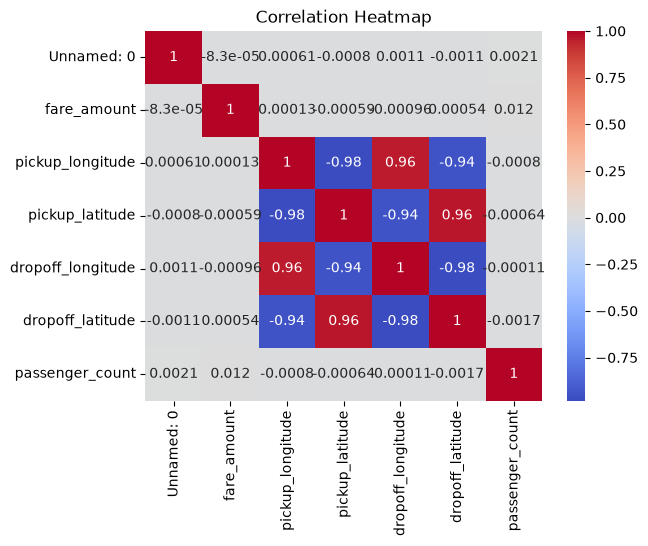

In [8]:
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
# 5. Select features and target
X = df[[
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count"
]]
y = df["fare_amount"]

In [10]:
# 6. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
# 7. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

In [12]:
# 8. Random Forest Regression
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [13]:
# 9. Evaluate models
for name, pred in [
    ("Linear Regression", pred_lr),
    ("Random Forest", pred_rf)
]:
    print("\n", name)
    print("R2 Score:", r2_score(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("MAE:", mean_absolute_error(y_test, pred))


 Linear Regression
R2 Score: 0.00020886416089083149
RMSE: 4.136532377906318
MAE: 3.2802906065476742

 Random Forest
R2 Score: 0.7084477239379476
RMSE: 2.2337779783215947
MAE: 1.573362280136913
